# A mock galaxy, fitted on the Apple GPU

Build a mock galaxy (photometry and a spectrum), look at it, fit it with nested sampling and
check how well the input values come back. On an Apple Silicon Mac with `pip install ceridwen`
(macOS 26, Python 3.12 or newer) the whole notebook runs on the GPU in float32: `import ceridwen`
sees the GPU and says so, nothing to configure. Anywhere else the same cells run in float64 on
the CPU (or an NVIDIA GPU). `docs/mac_gpu.md` says what float32 mode guarantees.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

import ceridwen                                   # on a Mac: picks the GPU, float32 mode
from ceridwen import SSPData, CSPBasis, SedModel, fitSED, PostProcess
from ceridwen.observation import Photometry, Spectrum
from ceridwen.broadening import Instrument
from ceridwen.cosmology import Cosmology
from ceridwen.model import logsfr_ratios_to_sfh
from ceridwen.priors import Uniform, ClippedNormal, StudentT
from ceridwen.ssps import fetch_grid
from ceridwen.precision import precision_name

print("JAX device :", jax.devices())
print("precision  :", precision_name())

Platform 'mtl' is experimental and not all JAX functionality may be correctly supported!


/var/folders/vd/kv9mg1cx6tdfwmlfx2m5qfr80000gr/T/ipykernel_68570/1021589394.py:7: UserWarning: float32 mode: JAX's default backend is the Apple GPU (mtl), which has no float64.  Evidences, gradients and the sampler state are float32 (docs/mac_gpu.md); for a float64 fit set JAX_PLATFORMS=cpu
  import ceridwen                                   # on a Mac: picks the GPU, float32 mode


JAX device : [MtlDevice(id=0)]
precision  : float32


## 1. The forward model

A published SSP grid (fetched once, 67 MB), a five-bin non-parametric star-formation history,
constant metallicity and diffuse dust, at redshift 1. Nebular emission is off here so that
the notebook needs no FSPS data files; `add_neb=True` plus `sps_home=` and priors on
`gas_logz` / `gas_logu` switch it on.

In [2]:
ssp = SSPData.load(fetch_grid("mist_miles_chab"))

ZRED = 1.0
N_TIME = 5                                        # SFH bins -> 4 free logsfr_ratios
cosmo = Cosmology.planck18()
lookback = jnp.linspace(0.0, float(cosmo.age(ZRED)), N_TIME)   # Gyr, today at index 0

csp = CSPBasis(ssp, lookback_time=lookback, zh_const=True, sfh_interp="step",
               add_dust=False, add_diffuse_dust=True, add_neb=False,
               cosmo=cosmo, verbose=False)
sfh_times_yr = np.array(csp.sfh_times)

def sfh_transform(theta, _t=sfh_times_yr):
    return logsfr_ratios_to_sfh(theta["logsfr_ratios"], sfh_times_yr=_t)

## 2. The mock observations

Twelve bands from the far UV to the mid infrared and a 1000-pixel spectrum covering the rest-frame
optical, all predicted from one chosen set of true parameters, then perturbed with Gaussian noise
(signal-to-noise 20 per band, 10 per pixel).

In [3]:
FILTERS = ["galex_FUV", "galex_NUV", "sdss_u0", "sdss_g0", "sdss_r0", "sdss_i0", "sdss_z0",
           "twomass_J", "twomass_H", "twomass_Ks", "wise_w1", "wise_w2"]
WAVE_OBS = np.linspace(7000.0, 16000.0, 1000)    # observed-frame Angstrom (rest 3500-8000)

TRUTH = {"logsfr_ratios": jnp.array([0.4, 0.2, -0.2, -0.6]),
         "logmass": jnp.array([10.3]),
         "logzsol": jnp.array([-0.3]),
         "diffuse_tau_kc": jnp.array([0.6]),
         "diffuse_dust_index": jnp.array([-0.5])}

PRIORS = {"logsfr_ratios": StudentT(mean=0.0, scale=1.0, df=2.0),
          "logmass": Uniform(low=9.0, high=12.0),
          "logzsol": Uniform(low=-2.0, high=0.2),
          "diffuse_tau_kc": ClippedNormal(mean=0.3, sigma=1.0, low=0.0, high=4.0),
          "diffuse_dust_index": Uniform(low=-1.0, high=0.4)}

def observations(phot_flux, phot_err, spec_flux, spec_err):
    return [Photometry(filters=FILTERS, flux=phot_flux, uncertainty=phot_err, name="phot"),
            Spectrum(wavelength=WAVE_OBS, flux=spec_flux, uncertainty=spec_err,
                     instrument=Instrument.sigma_kms(150.0), name="spec")]

def model_for(obs, init):
    return SedModel(csp, obs, priors=PRIORS, transforms={"sfh": sfh_transform},
                    free_param_init=init, zred=ZRED)

# the noise-free truth: a model with placeholder data, evaluated at TRUTH
truth_model = model_for(observations(np.zeros(len(FILTERS)), np.ones(len(FILTERS)),
                                     np.zeros(WAVE_OBS.size), np.ones(WAVE_OBS.size)), TRUTH)
true = truth_model.predict(truth_model.theta_init)

rng = np.random.default_rng(1)
phot_err = np.abs(np.asarray(true["phot"], float)) / 20.0
spec_err = np.abs(np.asarray(true["spec"], float)) / 10.0
phot_obs = np.asarray(true["phot"], float) + phot_err * rng.normal(size=phot_err.size)
spec_obs = np.asarray(true["spec"], float) + spec_err * rng.normal(size=spec_err.size)

obs = observations(phot_obs, phot_err, spec_obs, spec_err)

/Users/amanda/Desktop/PhD/Tools/ceridwen_macgpu_A/ceridwen/broadening.py:934: UserWarning: instrument narrower than the SSP library at 156 of 1000 pixels (15.6 %, 7000-16000 A): the continuum is delivered at library resolution there, which is correct for a coarse grid; if the instrument is really finer, use a finer grid; if the number is wrong, check the Instrument unit
  warnings.warn(


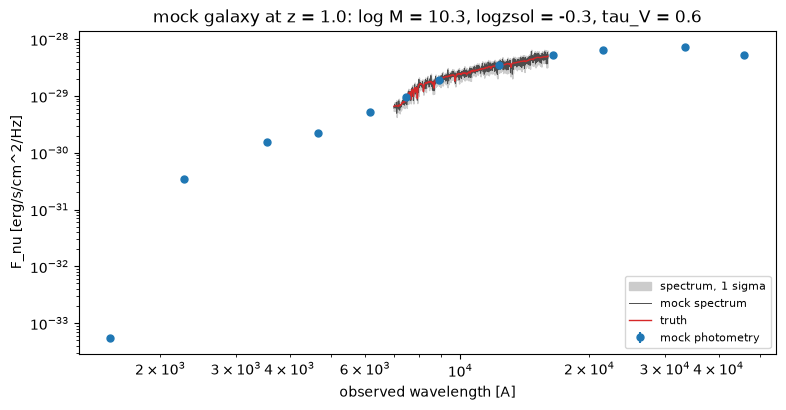

In [4]:
MAGGIE_TO_CGS = 3631e-23                          # 1 maggie = 3631 Jy = 3.631e-20 erg/s/cm^2/Hz
wave_eff = np.array([f.wave_effective for f in obs[0].filters])

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(WAVE_OBS, spec_obs - spec_err, spec_obs + spec_err, color="0.8", label="spectrum, 1 sigma")
ax.plot(WAVE_OBS, spec_obs, color="0.3", lw=0.7, label="mock spectrum")
ax.plot(WAVE_OBS, np.asarray(true["spec"]), color="C3", lw=1.0, label="truth")
ax.errorbar(wave_eff, phot_obs * MAGGIE_TO_CGS, yerr=phot_err * MAGGIE_TO_CGS, fmt="o", color="C0",
            ms=5, label="mock photometry")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("observed wavelength [A]"); ax.set_ylabel("F_nu [erg/s/cm^2/Hz]")
ax.set_title(f"mock galaxy at z = {ZRED}: log M = {float(TRUTH['logmass'][0]):.1f}, "
             f"logzsol = {float(TRUTH['logzsol'][0]):.1f}, tau_V = {float(TRUTH['diffuse_tau_kc'][0]):.1f}")
ax.legend(loc="lower right", fontsize=8)
plt.show()

## 3. The fit

`fitSED` builds the likelihood, runs nested sampling and writes `ceridwen_result.h5`. Its
header shows the device and the precision. On the M3 Pro this takes about ten minutes
(200 live points, 40 replaced per iteration, 30 slice steps each); the same settings on the CPU
take about four times longer in float64.

Compare the evidence `ln Z` only with fits of the same precision and sampler settings: a
float32 `ln Z` is 1-2 nats below the float64 value of the same data (`docs/mac_gpu.md`).

In [5]:
model = model_for(obs, {k: jnp.zeros_like(v) + jnp.array([10.0]) if k == "logmass" else jnp.zeros_like(v)
                        for k, v in TRUTH.items()})

result = fitSED(model, sampler="nested", rng_key=jax.random.PRNGKey(0),
                sampler_kwargs={"num_live": 200, "num_delete": 40, "num_inner_steps": 30},
                output_dir="apple_gpu_mock_fit", verbose=True)
print(f"ln Z = {result.log_evidence:.2f} +- {result.log_evidence_err:.2f}, "
      f"{result.n_likelihood_calls:,} likelihood calls, {result.wall_time_s:.0f} s")

ceridwen.fitSED


  Device      : MTL  (mtl:0)


  Precision   : float32  (float32 mode, docs/mac_gpu.md: ln Z and gradients are float32, not comparable bit for bit with a float64 fit)


                ^ Apple GPU (float32)


  Sampler     : nested


...

    Sampler run      :    342.1 s


    Derived mfrac    :    0.194 s


    HDF5 write       :    0.126 s


    Total fitSED     :    342.5 s


ln Z = 66943.11 +- 0.29, 136,800 likelihood calls, 339 s


## 4. How well did the truth come back?

`PostProcess` resamples the run to equal weights and pushes every draw through the forward
model, so the posterior-predictive spectrum and photometry can be drawn over the data.

The mass comes back a little low, in the formed and in the surviving mass alike, while the
star-formation-history ratios have wide, lopsided intervals: with one noise realisation and
200 live points the fit trades old mass against a slightly older history and more dust, the
usual mass, age and dust degeneracy. A float64 CPU fit of the same mock lands in the same
place, so this is the data and the sampler settings, not the precision. For a science fit use
`num_live=500` or more, and a spectrum with emission lines if you have one.

In [6]:
pp = PostProcess(model, result, n_samples=2000)
out = pp.run()

print(f"{'parameter':22s} {'truth':>8s}   {'median':>8s}  (16-84 %)")
names = []
for name, value in TRUTH.items():
    draws = np.asarray(out["theta"][name]).reshape(len(out["theta"]["logmass"]), -1)
    for j, t in enumerate(np.ravel(np.asarray(value))):
        lo, med, hi = np.percentile(draws[:, j], [16, 50, 84])
        label = name if draws.shape[1] == 1 else f"{name}[{j}]"
        names.append((label, draws[:, j], float(t)))
        print(f"{label:22s} {t:+8.3f}   {med:+8.3f}  (-{med - lo:.3f} / +{hi - med:.3f})")

# logmass is the mass FORMED; what the light traces is closer to the SURVIVING mass (stars and
# remnants), mfrac times the formed mass, from the grid's surviving-mass table
mfrac_true = float(csp.surviving_mass_fraction({"sfh": sfh_transform(TRUTH), "logzsol": TRUTH["logzsol"]}))
sfh = out["extras"]["sfh"]
for label, draws, t in [("log mass_formed", np.log10(sfh["mass_formed"]), float(TRUTH["logmass"][0])),
                        ("mfrac (surviving/formed)", sfh["mfrac"], mfrac_true),
                        ("log mass_surviving", np.log10(sfh["mass_surviving"]), float(TRUTH["logmass"][0]) + np.log10(mfrac_true))]:
    lo, med, hi = np.percentile(draws, [16, 50, 84])
    print(f"{label:22s} {t:+8.3f}   {med:+8.3f}  (-{med - lo:.3f} / +{hi - med:.3f})")

parameter                 truth     median  (16-84 %)
logsfr_ratios[0]         +0.400     -0.139  (-0.654 / +0.692)
logsfr_ratios[1]         +0.200     +0.368  (-0.516 / +0.426)
logsfr_ratios[2]         -0.200     +0.188  (-0.594 / +0.853)
logsfr_ratios[3]         -0.600     +0.291  (-0.647 / +0.746)
logmass                 +10.300    +10.223  (-0.035 / +0.053)
logzsol                  -0.300     -0.291  (-0.069 / +0.054)
diffuse_tau_kc           +0.600     +0.661  (-0.059 / +0.062)
diffuse_dust_index       -0.500     -0.451  (-0.043 / +0.041)
log mass_formed         +10.300    +10.223  (-0.035 / +0.053)
mfrac (surviving/formed)   +0.625     +0.642  (-0.012 / +0.009)
log mass_surviving      +10.096    +10.030  (-0.030 / +0.045)


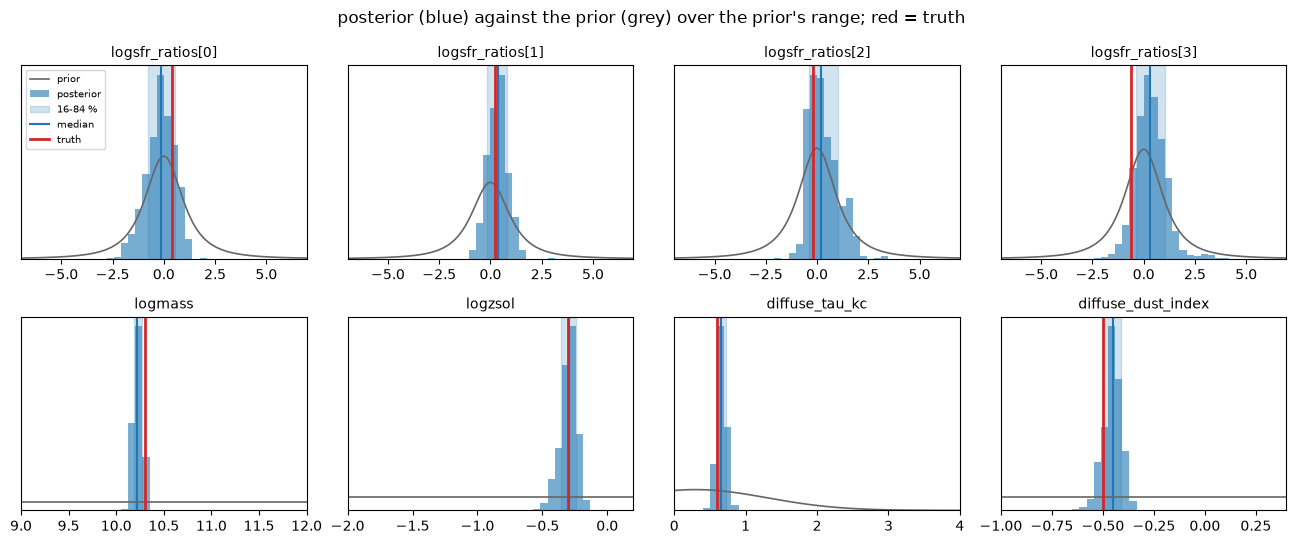

In [7]:
def prior_range(prior):
    """The prior's own range: its bounds for a bounded prior, its central 98 % for an unbounded one."""
    lo, hi = (float(x) for x in prior.range)
    if not np.isfinite(prior.bounds[0]) if not callable(prior.bounds) else not np.isfinite(prior.bounds()[0]):
        lo, hi = (float(x) for x in prior.tfp_dist().quantile(jnp.array([0.01, 0.99])))
    return lo, hi

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, (label, draws, t) in zip(axes.ravel(), names):
    prior = PRIORS[label.split("[")[0]]
    lo, hi = prior_range(prior)
    x = np.linspace(lo, hi, 400)
    ax.plot(x, np.exp(np.asarray(prior.logpdf(jnp.asarray(x)))), color="0.4", lw=1.2, label="prior")
    ax.hist(draws, bins=40, range=(lo, hi), color="C0", alpha=0.6, density=True, label="posterior")
    q16, q50, q84 = np.percentile(draws, [16, 50, 84])
    ax.axvspan(q16, q84, color="C0", alpha=0.2, label="16-84 %")
    ax.axvline(q50, color="C0", lw=1.5, label="median")
    ax.axvline(t, color="C3", lw=2, label="truth")
    ax.set_xlim(lo, hi); ax.set_yticks([]); ax.set_title(label, fontsize=10)
axes[0, 0].legend(fontsize=7, loc="upper left")
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
fig.suptitle("posterior (blue) against the prior (grey) over the prior's range; red = truth")
plt.tight_layout(); plt.show()

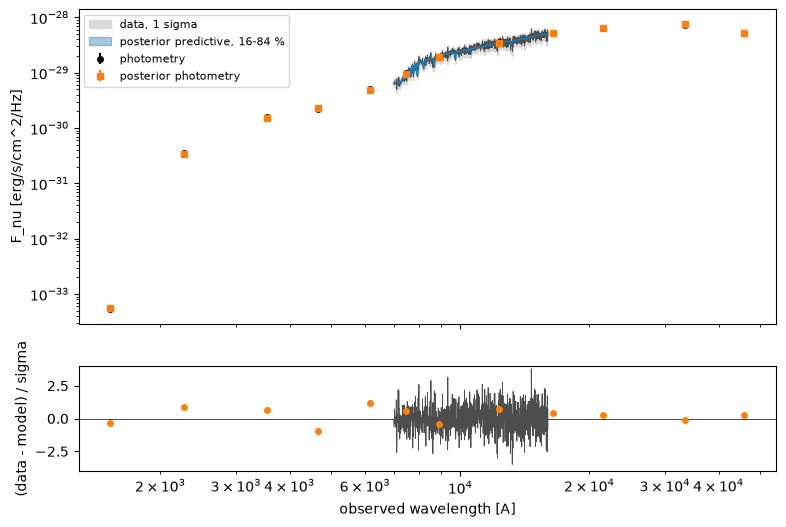

In [8]:
spec_draws = np.asarray(out["prediction"]["spectra"]["spec"])
phot_draws = np.asarray(out["prediction"]["photometry"]["phot"])
s16, s50, s84 = np.percentile(spec_draws, [16, 50, 84], axis=0)
p16, p50, p84 = np.percentile(phot_draws, [16, 50, 84], axis=0)

fig, (ax, res) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.fill_between(WAVE_OBS, spec_obs - spec_err, spec_obs + spec_err, color="0.85", label="data, 1 sigma")
ax.plot(WAVE_OBS, spec_obs, color="0.3", lw=0.6)
ax.fill_between(WAVE_OBS, s16, s84, color="C0", alpha=0.4, label="posterior predictive, 16-84 %")
ax.plot(WAVE_OBS, s50, color="C0", lw=1.0)
ax.errorbar(wave_eff, phot_obs * MAGGIE_TO_CGS, yerr=phot_err * MAGGIE_TO_CGS, fmt="o", color="k", ms=4, label="photometry")
ax.errorbar(wave_eff, p50 * MAGGIE_TO_CGS, yerr=[(p50 - p16) * MAGGIE_TO_CGS, (p84 - p50) * MAGGIE_TO_CGS],
            fmt="s", color="C1", ms=4, label="posterior photometry")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylabel("F_nu [erg/s/cm^2/Hz]"); ax.legend(fontsize=8)
res.axhline(0, color="k", lw=0.5)
res.plot(WAVE_OBS, (spec_obs - s50) / spec_err, color="0.3", lw=0.6)
res.plot(wave_eff, (phot_obs - p50) / phot_err, "o", color="C1", ms=4)
res.set_ylim(-4, 4); res.set_ylabel("(data - model) / sigma"); res.set_xlabel("observed wavelength [A]")
plt.show()